In [1]:
# Genre classification with logistic regression, Decision tree classifier, Random forest classifier

# Compare the accuracies of these models and pick the one that has the best accuracy.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_rows', None)

# print the songs that have no genre
df = pd.read_csv("../data/Non-temporal/data.csv")
# print("Songs with no genre:")
# songs_with_no_genre = df[df['artist_genres'].isnull()]
# print("Songs with no genre:")
# songs_with_no_genre.count()

# songs with multiple genres
songs_with_multiple_genres = df[df['artist_genres'].str.contains(",", na=False)]
print("Songs with multiple genres:")
songs_with_multiple_genres.head()

Songs with multiple genres:


,Unnamed: 0,id,Title,Primary Artists,Featuring Artists,Danceability,Energy,Speechiness,Acousticness,Instrumentalness,...,detected_languages,num_languages,language_confidences,artist_id,explicit,track_popularity,artist_followers,artist_genres,artist_popularity,Loudness
0,0,47EiUVwUp4C9fGccaPuUCS,dákiti,"bad bunny, jhayco",NaN,0.731,0.573,0.054,0.401,0.000,...,SPANISH,1,SPANISH: 1.0,4q3ewBCX7sLwd24euuV69X,True,78,102185553.0,"reggaeton, trap latino, urbano latino, latin",95.0,-10.059
2,2,3qQbCzHBycnDpGskqOWY0E,ella baila sola,"eslabon armado, peso pluma",NaN,0.668,0.758,0.033,0.483,0.000,...,SPANISH,1,SPANISH: 1.0,0XeEobZplHxzM9QzFQWLiR,False,73,6434994.0,"corridos tumbados, sad sierreño, corrido, sier...",75.0,-5.176
22,22,4fSIb4hdOQ151TILNsSEaF,todo de ti,rauw alejandro,NaN,0.780,0.718,0.051,0.310,0.000,...,SPANISH,1,SPANISH: 1.0,1mcTU81TzQhprhouKaTkpq,True,72,30984858.0,"reggaeton, urbano latino, trap latino, latin",88.0,-3.605
24,24,3dnP0JxCgygwQH9Gm7q7nb,ella baila sola,"eslabon armado, peso pluma",NaN,0.668,0.758,0.033,0.483,0.000,...,SPANISH,1,SPANISH: 1.0,0XeEobZplHxzM9QzFQWLiR,False,76,6434994.0,"corridos tumbados, sad sierreño, corrido, sier...",75.0,-5.176
25,25,7ro0hRteUMfnOioTFI5TG1,where she goes,bad bunny,NaN,0.652,0.800,0.061,0.143,0.629,...,SPANISH,1,SPANISH: 1.0,4q3ewBCX7sLwd24euuV69X,True,75,102185553.0,"reggaeton, trap latino, urbano latino, latin",95.0,-4.019


In [3]:
# First work on assigning super genres to songs 
genre_mapping = {
    'pop': ["pop", "k-pop", "soft space pop", "pop urbaine", "colombian pop", "latin pop", "art pop", "pop urbano", "funk pop", "brazilian pop", "german pop", "pop punk", "acoustic pop", "afropop", "baroque pop", "bedroom pop", "britpop", "bubblegum pop", "dansk pop", "desi pop", "dream pop", "europop", "finnish pop", "flamenco pop", "french indie pop", "french pop", "germain pop", "gujarati pop", "hindi pop", "hyperpop", "indonesian pop", "j-pop", "k-pop", "latin pop", "nederpop", "norwegian pop", "pop", "pop country", "pop punk", "pop urbaine", "pop urbano", "punjabi pop", "soft pop","swedish pop", "synthpop", "t-pop", "tamil pop", "telugu pop", "turkish pop", "grupera", "schlager", "schlagerparty", "variété française", "tollywood", "neomelodico", "anime", "bollywood", "brega", "chanson", "desi", "kollywood"],
    'hip hop': ["arabic hip hop", "brazilian hip hop", "desi hip hop", "east coast hip hop", "egyptian hip hop", "german hip hop", "ghanaian hip hop", "hardcore hip hop", "hindi hip hop", "hip hop", "indonesian hip hop", "latin hip hop", "mexican hip hop", "old school hip hop", "punjabi hip hop", "southern hip hop", "tamil hip hop", "turkish hip hop", "underground hip hop", "west coast hip hop", "drill", "new york drill", "uk drill", "brooklyn drill", "chicago drill", "boom bap", "dancehall", "hiplife", "horrorcore", "hyphy", "ragga", "shatta", "phonk", "brazilian phonk", "drift phonk", "rkt"],
    'rock' : ["argentine rock", "art rock", "blues rock", "celtic rock", "classic rock", "country rock", "garage rock", "glam rock", "hard rock", "industrial rock", "j-rock", "k-rock", "latin rock", "progressive rock", "psychedelic rock", "rock", "rock and roll", "rock en español", "rockabilly", "soft rock", "southern rock", "yacht rock", "aor", "emo", "grunge", "punk", "skate punk", "celtic punk", "madchester", "neue deutsche welle", "new wave", "post-grunge", "post-hardcore", "screamo", "neo-psychedelic", "darkwave", "mizrahi", "surf"],
    'indie': ["french indie pop", "german indie pop", "hindi indie", "indian indie", "indie", "indie folk", "indie r&b", "indie rock", "indonesian indie", "latin indie", "lo-fi indie", "mexican indie"],
    'metal': ["glam metal", "heavy metal", "industrial metal", "metal", "metalcore", "nu metal", "progressive metal", "thrash metal"],
    'funk': ["brazilian funk", "brega funk", "funk", "funk carioca", "funk consciente", "funk de bh", "funk melody", "funk pop", "funk rock", "funky house", "g-funk", "agronejo", "reggae", "roots reggae"],
    'trap': ["argentine trap", "brazilian trap", "chilean trap", "italian trap", "trap", "trap funk", "trap latino", "trap metal", "trap soul", "neoperreo"],
    'soul': ["afro soul", "classic soul", "neo soul", "northern soul", "retro soul", "soul", "soul blues", "motown"],
    'rap': ["cloud rap", "emo rap", "french rap", "gangster rap", "k-rap", "melodic rap", "rage rap", "rap", "rap metal", "ska", "dembow", "dembow belico"],
    'r&b': ["afro r&b", "dark r&b", "french r&b", "indonesian r&b", "r&b", "quiet storm"],
    'country': ["acoustic country", "classic country", "country", "country hip hop", "red dirt", "banda"],
    'alternative': ["alternative dance", "alternative hip hop", "alternative metal", "alternative r&b,", "alternative rock", "latin alternative"],
    'folk': ["folk", "folk pop", "folk punk", "folk rock", "celtic", "corrido", "corridos bélicos", "corridos tumbados", "laïko", "mariachi", "norteño", "norteño-sax", "ranchera", "raï", "sad sierreño", "sea shanties", "seresta", "sierreño", "vallenato", "villancicos", "sertanejo", "sertanejo universitário", "arabesk", "canzone napoletana", "italian singer-songwriter", "malay", "tejano"],
    'dance': ["dance pop", "eurodance", "italo dance", "latin dance", "tamil dance", "salsa", "salsa choke", "kizomba", "afrobeat", "afrobeats", "latin afrobeats", "afroswing", "bachata", "bhangra", "latin", "latin folk", "urbano latino", "samba", "alté", "arrocha", "axé", "azonto", "bacardi", "bolero", "chilean mambo", "cuarteto", "cumbia", "cumbia norteña", "cumbia sonidera", "disco", "flamenco", "flamenco urbano", "gujarati garba", "mambo", "merengue", "mpb", "nova mpb", "pagode", "pagode baiano", "soca", "piseiro", "forró", "forró tradicional"],
    'jazz': ["indonesian jazz", "jazz", "jazz blues", "vocal jazz", "adult standards", "big band", "swing", "doo-wop", "k-ballad", "modern blues", "fado"],
    'electronic': ["edm", "electro", "dubstep", "drum and bass", "electro corridos", "electrocumbia", "electronic", "electronica", "disco house", "electro house", "french house", "house", "progressive house", "slap house", "tech house", "tropical house", "witch house", "amapiano", "big room", "brazilian bass", "future bass", "gqom", "grime", "guaracha", "hypertechno", "industrial", "jersey club", "melodic bass", "moombahton", "progressive trance", "riddim", "techno", "tecnobrega", "tejano", "uk grime", "turreo", "afropiano", "reggaeton", "reggaeton chileno", "reggaeton mexa"],
    'religious': ["ccm", "christian", "christian hip hop", "christian pop", "worship", "sufi", "qawwali", "ghazal"],
    'performance': ["soundtrack", "música mexicana", "musicals", "murga"],
    'other': ["christmas", "comedy", "hollands"]
}

print(genre_mapping.keys())
# removing "NaN" songs 


dict_keys(['pop', 'hip hop', 'rock', 'indie', 'metal', 'funk', 'trap', 'soul', 'rap', 'r&b', 'country', 'alternative', 'folk', 'dance', 'jazz', 'electronic', 'religious', 'performance', 'other'])


In [4]:
# create empty pandas series
super_genres = pd.Series(dtype=str)
  
for index, row in df.iterrows():
    genre_counts = {} 
    if pd.notna(row['artist_genres']):
        # if there are multiple genres
        if "," in row['artist_genres']:
            # remove white spaces and split the genres based on the commas
            genres = [g.strip() for g in row['artist_genres'].split(",")]

            for genre in genres:
                for superclass, keywords in genre_mapping.items():
                    if genre in keywords:
                        # genre_counts.get(superclass, 0), tries to get the count for the superclass, if it does not exist, it returns 0, then we add 1 to it
                        genre_counts[superclass] = genre_counts.get(superclass, 0) + 1
                        # stop once we found the first match
                        break

           
            max_genre = max(genre_counts, key=genre_counts.get)
            super_genres.at[index] = max_genre
     
        # if there is only one genre
        else:
            for superclass, keywords in genre_mapping.items():
                for keyword in keywords:
                    if row['artist_genres'] == keyword:
                        super_genres.at[index] = superclass
                        break

    # else:
    #     # if the artist_genres does contain NaN it should be mapped to other
    #     super_genres.at[index] = "other"



df['super_genre'] = super_genres
del df['artist_genres']
df.head()
# save the dataframe to a new csv file
df.to_csv('../data/Non-temporal/songs_with_super_genres.csv', index=False)


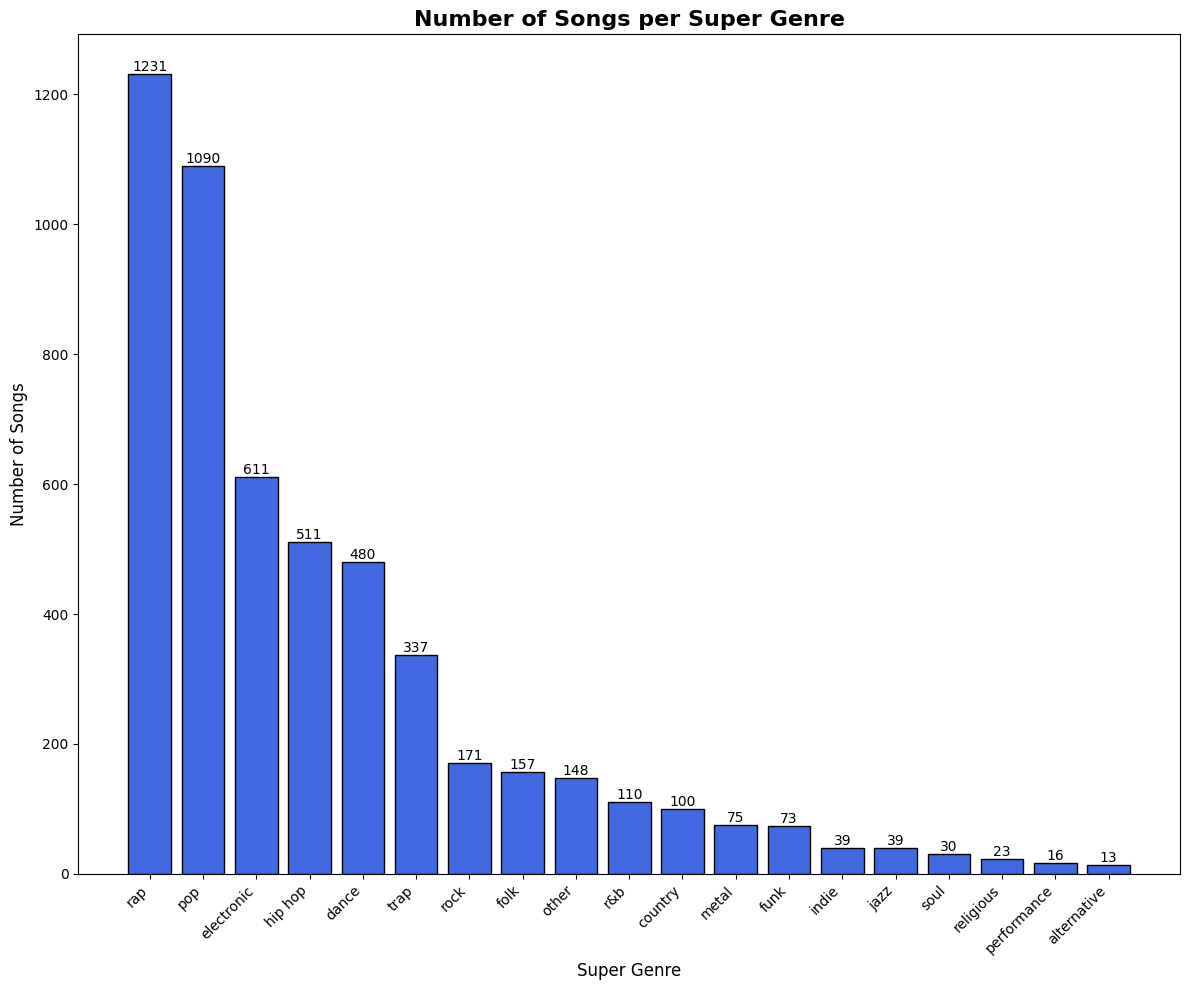

In [11]:
# Number of songs per super genre
super_genre_counts = df['super_genre'].value_counts()

plt.figure(figsize=(12, 10))
bars = plt.bar(super_genre_counts.index, super_genre_counts.values, color='royalblue', edgecolor='black')

plt.title('Number of Songs per Super Genre', fontsize=16, fontweight='bold')
plt.xlabel('Super Genre', fontsize=12)
plt.ylabel('Number of Songs', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom')

plt.tight_layout()
plt.savefig("songsSuperGenre.pdf")
plt.show()